In [1]:
!pip install -q pandas numpy matplotlib scikit-learn
print("All libraries installed successfully!")

All libraries installed successfully!


In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

np.random.seed(42)
rng = np.random.default_rng(42)

n = 600

df = pd.DataFrame({
    "patient_id": [f"SYN{i:04d}" for i in range(1, n + 1)],
    "age": rng.integers(18, 81, n),
    "bmi": np.clip(rng.normal(26.5, 5.2, n), 16, 45).round(1),
    "systolic_bp": np.clip(
        rng.normal(122, 16, n), 85, 190
    ).round().astype(int),
    "glucose_mg_dl": np.clip(
        rng.normal(103, 22, n), 65, 220
    ).round().astype(int),
    "cholesterol_mg_dl": np.clip(
        rng.normal(190, 30, n), 110, 320
    ).round().astype(int),
    "weekly_activity_hours": np.clip(
        rng.normal(3.5, 2.2, n), 0, 12
    ).round(1),
    "smoking_status": rng.choice(
        ["Never", "Former", "Current"],
        n, p=[0.62, 0.22, 0.16]
    ),
    "family_history": rng.choice(
        [0, 1], n, p=[0.68, 0.32]
    )
})

score = (
    (df["age"] >= 55).astype(int)
    + (df["bmi"] >= 30).astype(int)
    + (df["systolic_bp"] >= 140).astype(int)
    + (df["glucose_mg_dl"] >= 126).astype(int)
    + (df["cholesterol_mg_dl"] >= 240).astype(int)
    + (df["smoking_status"] == "Current").astype(int)
    + df["family_history"]
)

df["synthetic_risk_label"] = (score >= 3).astype(int)

df.to_csv("synthetic_healthcare_data.csv", index=False)

print("Dataset generated successfully!")
print("Total records:", len(df))
display(df.head(10))

Dataset generated successfully!
Total records: 600


,patient_id,age,bmi,systolic_bp,glucose_mg_dl,cholesterol_mg_dl,weekly_activity_hours,smoking_status,family_history,synthetic_risk_label
0,SYN0001,23,25.0,85,110,171,6.3,Never,0,0
1,SYN0002,66,26.0,95,107,204,0.0,Former,0,0
2,SYN0003,59,25.2,109,89,196,0.7,Former,0,0
3,SYN0004,45,27.3,113,103,209,1.2,Never,0,0
4,SYN0005,45,34.2,115,89,194,3.4,Never,0,0
5,SYN0006,72,16.0,123,79,215,2.7,Current,1,1
6,SYN0007,23,25.3,117,95,193,6.6,Never,0,0
7,SYN0008,61,27.4,139,79,214,5.6,Current,0,0
8,SYN0009,30,28.0,111,110,216,4.6,Never,0,0
9,SYN0010,23,24.6,108,78,166,3.8,Never,0,0


Dataset shape: (600, 10)

Missing values:


,Missing Values
patient_id,0
age,0
bmi,0
systolic_bp,0
glucose_mg_dl,0
cholesterol_mg_dl,0
weekly_activity_hours,0
smoking_status,0
family_history,0
synthetic_risk_label,0



Statistical summary:


,age,bmi,systolic_bp,glucose_mg_dl,cholesterol_mg_dl,weekly_activity_hours,family_history,synthetic_risk_label
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,49.04,26.36,122.27,100.25,191.28,3.62,0.30,0.16
std,18.26,5.16,16.11,20.87,30.38,2.11,0.46,0.37
min,18.00,16.00,85.00,65.00,110.00,0.00,0.00,0.00
25%,33.00,22.80,112.00,86.00,171.00,2.00,0.00,0.00
50%,49.00,26.60,122.50,101.00,192.00,3.50,0.00,0.00
75%,65.25,29.80,132.25,114.25,211.00,5.20,1.00,0.00
max,80.00,43.00,167.00,167.00,274.00,10.20,1.00,1.00



Synthetic label distribution:


,count
synthetic_risk_label,
0,505
1,95


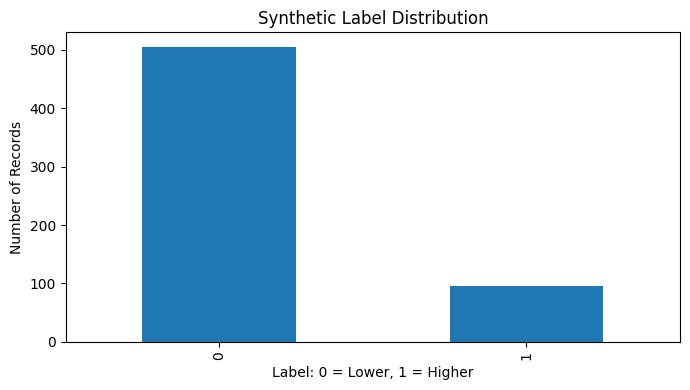

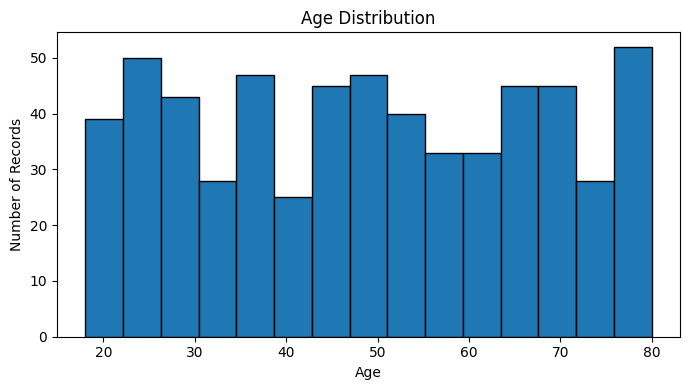

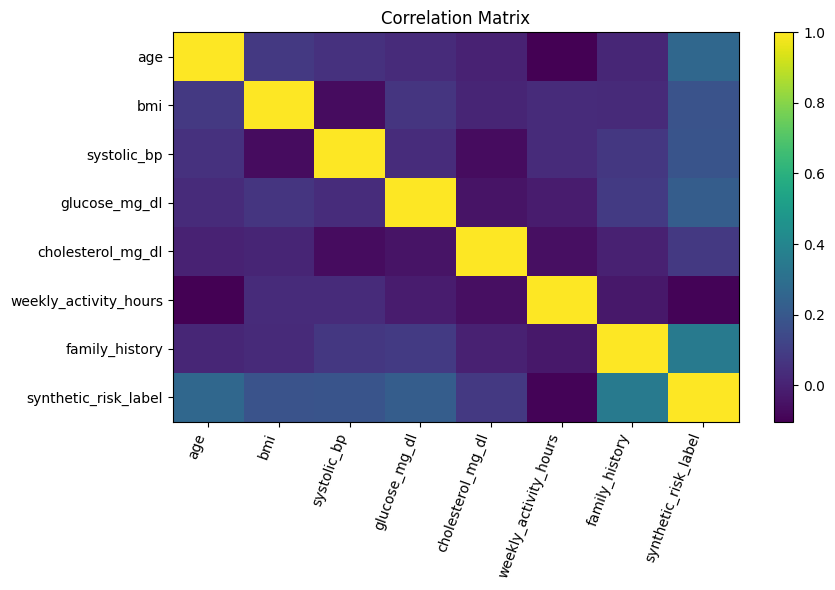

All charts generated successfully!


In [3]:
import matplotlib.pyplot as plt

Path("outputs").mkdir(exist_ok=True)

print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nSynthetic label distribution:")
display(df["synthetic_risk_label"].value_counts())

# Chart 1: Synthetic label distribution
df["synthetic_risk_label"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 4)
)
plt.title("Synthetic Label Distribution")
plt.xlabel("Label: 0 = Lower, 1 = Higher")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("outputs/synthetic_label_distribution.png")
plt.show()

# Chart 2: Age distribution
plt.figure(figsize=(7, 4))
plt.hist(df["age"], bins=15, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("outputs/age_distribution.png")
plt.show()

# Chart 3: Correlation matrix
cols = [
    "age", "bmi", "systolic_bp", "glucose_mg_dl",
    "cholesterol_mg_dl", "weekly_activity_hours",
    "family_history", "synthetic_risk_label"
]

corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(cols)), labels=cols, rotation=70, ha="right")
ax.set_yticks(range(len(cols)), labels=cols)
ax.set_title("Correlation Matrix")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig("outputs/correlation_matrix.png")
plt.show()

print("All charts generated successfully!")

Model training completed!
Training records: 480
Testing records: 120
Accuracy against synthetic labels: 0.917

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       101
           1       0.74      0.74      0.74        19

    accuracy                           0.92       120
   macro avg       0.84      0.84      0.84       120
weighted avg       0.92      0.92      0.92       120



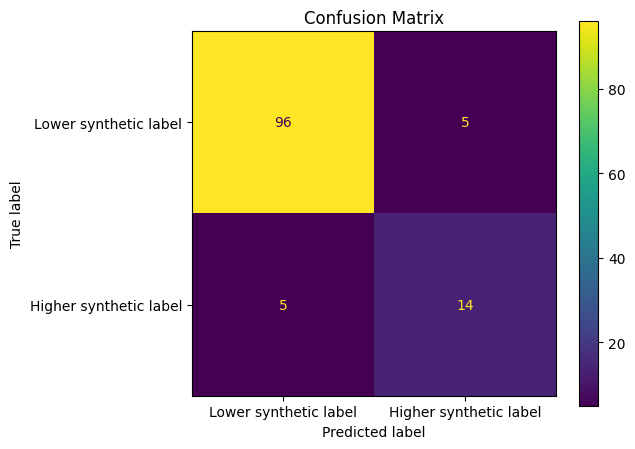

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

features = [
    "age", "bmi", "systolic_bp",
    "glucose_mg_dl", "cholesterol_mg_dl",
    "weekly_activity_hours", "smoking_status",
    "family_history"
]

X = pd.get_dummies(
    df[features],
    columns=["smoking_status"],
    dtype=int
)

y = df["synthetic_risk_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(
    "Accuracy against synthetic labels:",
    round(accuracy_score(y_test, predictions), 3)
)

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=[0, 1],
    display_labels=["Lower synthetic label", "Higher synthetic label"]
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png")
plt.show()

In [9]:
import zipfile
from pathlib import Path

with zipfile.ZipFile(
    "healthcare_project_outputs.zip", "w",
    zipfile.ZIP_DEFLATED
) as z:
    z.write("synthetic_healthcare_data.csv")

    for file in Path("outputs").glob("*.png"):
        z.write(file, arcname=f"outputs/{file.name}")

print("Project outputs saved successfully!")
print("CSV, charts and ZIP are ready.")

Project outputs saved successfully!
CSV, charts and ZIP are ready.
